# Session 5: CNN on MNIST and YOLOv8

This notebook contains structured tasks for building a CNN on MNIST and experimenting with Ultralytics YOLOv8 (pretrained inference and a short training example).

**Instructions:**
- Complete all tasks directly in this notebook.
- Keep your code clear and well-commented.
- Use `%matplotlib inline` for visualizations.
- If you need to install packages (e.g., `ultralytics`), use `%pip` in a cell.
- When using external datasets, do NOT upload them to GitHub.

### ***DO NOT UPLOAD LARGE DATASETS OR MODEL WEIGHTS TO GITHUB***
<hr>

## Task 1: Convolutional Neural Network on MNIST — Build, Train, Evaluate, Visualize
Train a simple CNN on the MNIST handwritten digits dataset. After training, generate predictions on the test set, compare them to ground truth labels, and visualize a few results.

**Why this matters:**
- MNIST is a classic entry point for image classification and CNNs.
- You will practice the full workflow: data loading, model definition, training, evaluation, and visualization.

**Steps:**
- Load MNIST with appropriate transforms (normalize).
- Define a small CNN (Conv → ReLU → Pool → FC).
- Train for a few epochs (2–3 for demo).
- Evaluate on the test set and compute accuracy.
- Visualize several test images with predicted and true labels.

**Hint:** Use `torchvision.datasets.MNIST`, `DataLoader`, `nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, and `nn.CrossEntropyLoss`.

In [1]:
# TODO: Setup environment and imports
# - Import torch, torchvision, numpy, matplotlib
# - Set random seeds and select device (cpu/cuda)
# - Enable %matplotlib inline if needed
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# same random numbers every run, so the results can be repeated
torch.manual_seed(0)
np.random.seed(0)

# use the GPU if this PyTorch install can see one, otherwise the CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cpu


In [2]:
# TODO: Load MNIST train/test datasets and create DataLoaders
# - Apply ToTensor and Normalize transforms
# - Create train_loader and test_loader

# the dataset is saved in the repo's datasets folder, which is in .gitignore so it doesn't get uploaded
data_dir = r'C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\datasets'

# ToTensor: image -> tensor (1, 28, 28) with values 0-1
# Normalize: subtract MNIST's mean (0.1307) and divide by its std (0.3081), so values are centered around 0
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_data = datasets.MNIST(root=data_dir, train=True, download=True, transform=transform)
test_data = datasets.MNIST(root=data_dir, train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

print('train images:', len(train_data), '| test images:', len(test_data))
print('one image:', train_data[0][0].shape)

train images: 60000 | test images: 10000
one image: torch.Size([1, 28, 28])


In [3]:
# TODO: Define a small CNN suitable for MNIST (1x28x28 input)
# - Use Conv2d, ReLU, MaxPool2d, Linear layers
# - Return logits for 10 classes
class MnistCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)    # 1x28x28  -> 16x28x28
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)   # 16x14x14 -> 32x14x14
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2)                             # halves height and width
        self.fc1 = nn.Linear(32 * 7 * 7, 10)                       # 32 maps of 7x7 -> 10 digit scores

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))   # -> 16x14x14
        x = self.pool(self.relu(self.conv2(x)))   # -> 32x7x7
        x = x.view(x.size(0), -1)                 # flatten to one long vector per image
        return self.fc1(x)                        # logits (raw scores), CrossEntropyLoss does the softmax

model = MnistCNN().to(device)
print(model)

MnistCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=10, bias=True)
)


In [4]:
# TODO: Set up optimizer and loss function
# - Choose Adam/SGD and CrossEntropyLoss
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# TODO: Implement a short training loop (2–3 epochs)
# - Print loss/accuracy per epoch
epochs = 3
for epoch in range(epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()               # 1. clear the old gradients
        outputs = model(images)             # 2. forward pass: predictions
        loss = criterion(outputs, labels)   # 3. how wrong the predictions are
        loss.backward()                     # 4. backward pass: gradients
        optimizer.step()                    # 5. update the weights

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    print(f'epoch {epoch + 1}/{epochs}: loss {running_loss / total:.4f}, training accuracy {100 * correct / total:.2f}%')

epoch 1/3: loss 0.1739, training accuracy 94.91%
epoch 2/3: loss 0.0568, training accuracy 98.23%
epoch 3/3: loss 0.0432, training accuracy 98.65%


In [5]:
# TODO: Evaluate on the test set and compute accuracy
# - Switch model to eval mode
# - Accumulate correct predictions and total
model.eval()
correct, total = 0, 0
all_predictions, all_labels = [], []

with torch.no_grad():   # no gradients needed when we only predict
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        predictions = model(images).argmax(dim=1)   # the class with the highest score

        correct += (predictions == labels).sum().item()
        total += labels.size(0)
        all_predictions.append(predictions.cpu())
        all_labels.append(labels.cpu())

all_predictions = torch.cat(all_predictions)
all_labels = torch.cat(all_labels)

print(f'test accuracy: {100 * correct / total:.2f}% ({correct} of {total})')
print('wrong predictions:', (all_predictions != all_labels).sum().item())

test accuracy: 98.64% (9864 of 10000)
wrong predictions: 136


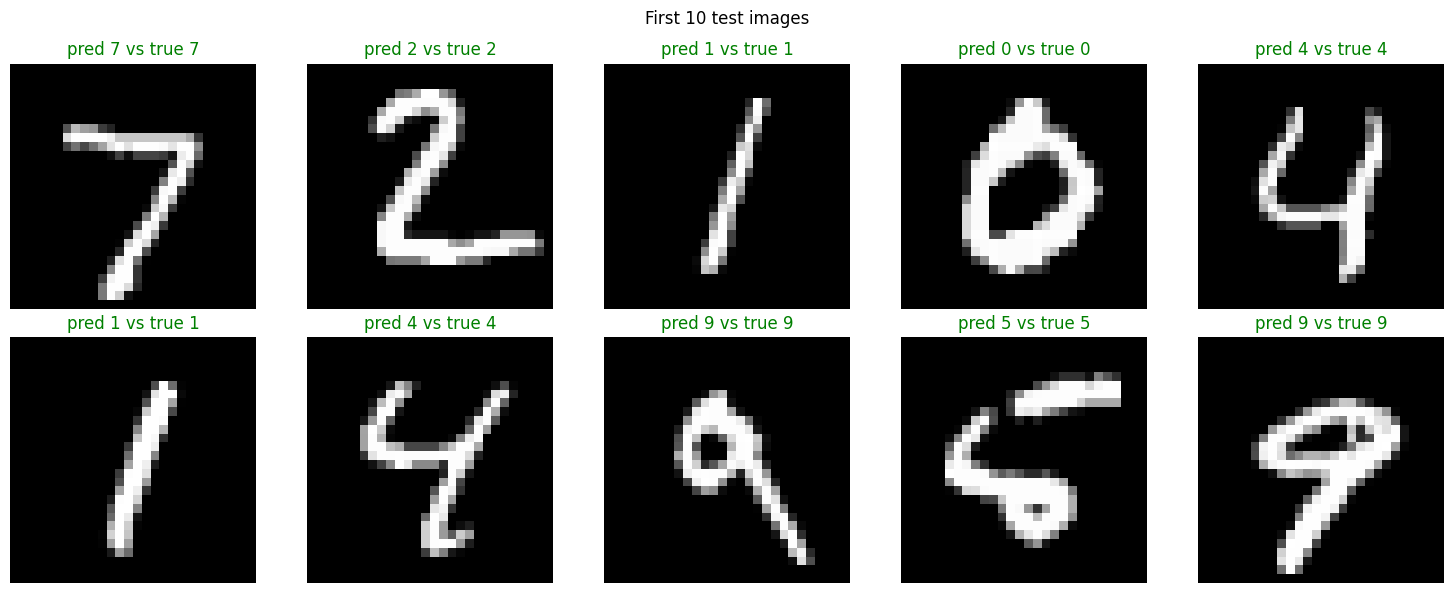

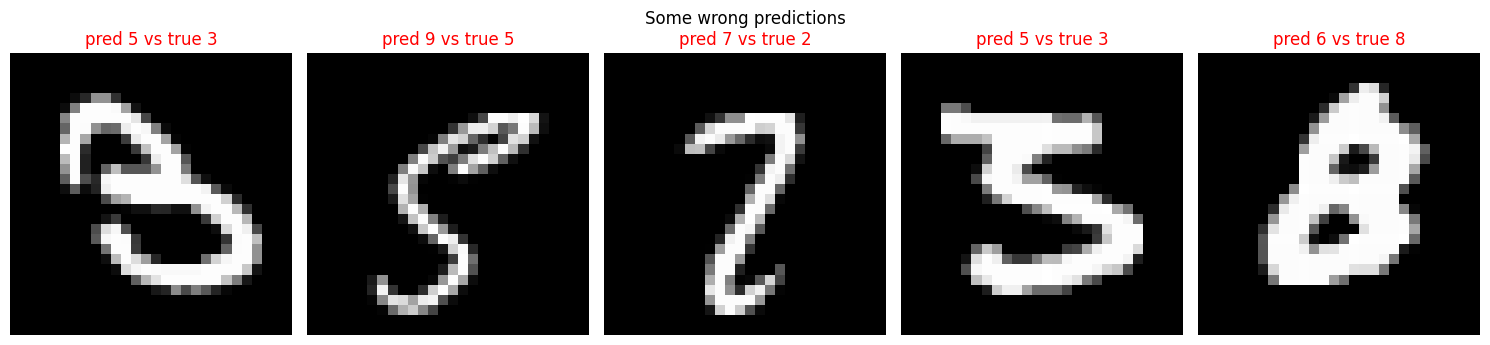

In [6]:
# TODO: Visualize a few test images with predicted and true labels
# - Sample a batch from test_loader
# - Run model and plot images with 'pred vs true' titles
images, labels = next(iter(test_loader))

model.eval()
with torch.no_grad():
    predictions = model(images.to(device)).argmax(dim=1).cpu()

plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap='gray')
    is_correct = predictions[i] == labels[i]
    plt.title(f'pred {predictions[i].item()} vs true {labels[i].item()}', color='green' if is_correct else 'red')
    plt.axis('off')
plt.suptitle('First 10 test images')
plt.tight_layout()
plt.show()

# also show some of the digits the model got wrong
wrong = (all_predictions != all_labels).nonzero().squeeze(1)[:5]
plt.figure(figsize=(15, 3.5))
for i, index in enumerate(wrong):
    image, label = test_data[index.item()]
    plt.subplot(1, 5, i + 1)
    plt.imshow(image.squeeze(), cmap='gray')
    plt.title(f'pred {all_predictions[index].item()} vs true {label}', color='red')
    plt.axis('off')
plt.suptitle('Some wrong predictions')
plt.tight_layout()
plt.show()

## Task 2: YOLOv8 Pretrained Predictions (No Training)
Use a pretrained YOLOv8 model to run inference on any image of your choice and visualize detections.

**Why this matters:**
- Demonstrates transfer learning and using pretrained models for object detection.
- Learn how to quickly test a detector on real images.

**Steps:**
- Install `ultralytics` if not available.
- Load a YOLOv8 model (e.g., `yolov8n.pt`).
- Run predictions on an image path.
- Visualize the detections (boxes, labels, confidences).

**Hint:** Use `from ultralytics import YOLO`, `YOLO('yolov8n.pt')`, and `model.predict(source=...)`.

In [7]:
# TODO: Install ultralytics if needed (pip)
# %pip install ultralytics
# - Restart the kernel if required after installation

# ultralytics is already installed in my ml_lab environment, so i only check it here
import ultralytics
print('ultralytics version:', ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\habib\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics version: 8.4.211


person: confidence 0.81, box (3147, 2583) to (3390, 3060)
person: confidence 0.74, box (320, 2581) to (682, 3235)
car: confidence 0.72, box (1648, 2561) to (2088, 2901)
person: confidence 0.71, box (4280, 2580) to (4476, 3240)
person: confidence 0.58, box (1143, 2554) to (1281, 2842)
traffic light: confidence 0.53, box (1580, 2078) to (1671, 2290)
person: confidence 0.51, box (4137, 2564) to (4304, 3225)
person: confidence 0.47, box (1034, 2558) to (1136, 2835)
bus: confidence 0.47, box (1559, 2437) to (2317, 2833)
traffic light: confidence 0.45, box (4107, 1374) to (4225, 1636)
traffic light: confidence 0.43, box (238, 1837) to (367, 2176)
person: confidence 0.43, box (4613, 2600) to (4736, 2897)
truck: confidence 0.41, box (2672, 2505) to (2905, 2750)
traffic light: confidence 0.41, box (3823, 2183) to (3878, 2263)
truck: confidence 0.39, box (3623, 2514) to (4101, 2907)
car: confidence 0.38, box (3622, 2516) to (4105, 2905)
person: confidence 0.36, box (1313, 2564) to (1433, 2858)
p

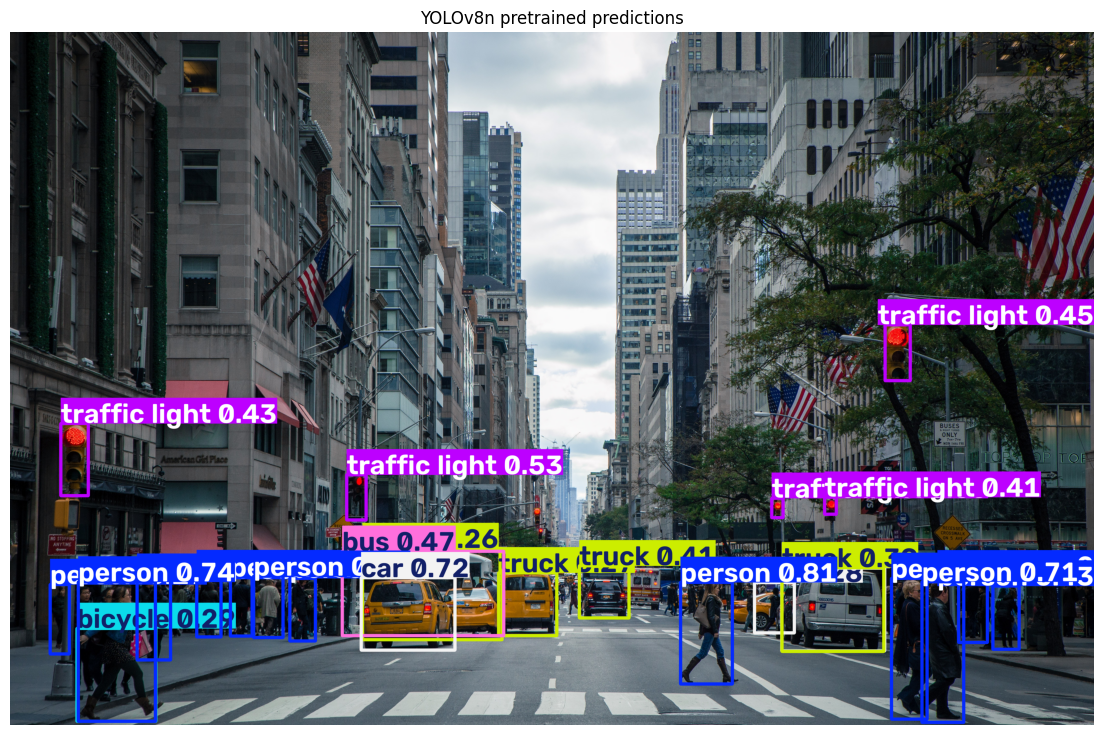

In [8]:
# TODO: Load a pretrained YOLOv8 model and run predictions on an image
# - Visualize results with matplotlib (convert BGR->RGB if using OpenCV)
import cv2
from ultralytics import YOLO

# yolov8n = the smallest ("nano") YOLOv8, already trained on the 80 COCO classes
pretrained_model = YOLO('yolov8n.pt')   # downloads the weights the first time (*.pt is in .gitignore)

image_path = r'C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\Session4\YOLO\images\city_scene.jpg'
results = pretrained_model.predict(source=image_path, conf=0.25, verbose=False)
result = results[0]   # one result per image

# print every detection: class name, confidence, box corners
for box in result.boxes:
    class_name = result.names[int(box.cls)]
    x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
    print(f'{class_name}: confidence {float(box.conf):.2f}, box ({x1}, {y1}) to ({x2}, {y2})')
print('total detections:', len(result.boxes))

# result.plot() draws the boxes, labels and confidences, and returns a BGR image
annotated = result.plot()
plt.figure(figsize=(14, 9))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title('YOLOv8n pretrained predictions')
plt.axis('off')
plt.show()

## Task 3: YOLOv8 Training Example (Small Demo)
Choose any small dataset (e.g., from Roboflow or Kaggle) and train a YOLOv8 model for a few epochs (e.g., 3) as a demonstration. Then run predictions with the trained model.

**Why this matters:**
- Understand the end-to-end YOLO training pipeline.
- See how dataset configuration (classes, paths) connects to training code.

**Steps:**
- Prepare your dataset directory and a `data.yaml` describing train/val paths and class names.
- Train a small model (e.g., `yolov8n.pt`) for ~3 epochs.
- Run predictions on a few sample images.
- Reflect: Are the predictions what you expected? Why or why not?

**Notes:**
- Do NOT upload datasets to GitHub. Keep them locally or use a data hosting service.
- Training for 3 epochs is just for demonstration; try longer training later.
- If you can't use GPU, small images and fewer epochs help.
- If you can't use GPU, you can train your models on Kaggle or Google Colab in the future for free access to GPUs on their servers

In [9]:
# TODO: Provide path to your YOLOv8 data.yaml
# - Ensure train/val image directories and class names are correct

# coco8 is a tiny demo dataset from Ultralytics: 4 training images and 4 validation images, 80 COCO classes
# its data.yaml ships with ultralytics, and the images download automatically the first time (about 1 MB)
from ultralytics.utils import DATASETS_DIR
from ultralytics.utils.checks import check_yaml
import yaml

data_yaml = check_yaml('coco8.yaml')   # full path to the data.yaml file
print('data.yaml:', data_yaml)
print('datasets folder:', DATASETS_DIR)

with open(data_yaml, encoding='utf-8') as f:
    data_config = yaml.safe_load(f)
print('train images:', data_config['train'], '| val images:', data_config['val'])
print('number of classes:', len(data_config['names']), '| first 5:', list(data_config['names'].values())[:5])

data.yaml: C:\Users\habib\anaconda3\envs\ml_lab\Lib\site-packages\ultralytics\cfg\datasets\coco8.yaml
datasets folder: C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\tasks\datasets
train images: images/train | val images: images/val
number of classes: 80 | first 5: ['person', 'bicycle', 'car', 'motorcycle', 'airplane']


In [10]:
# TODO: Train YOLOv8 for a few epochs (e.g., 3)
# - Save the path to best weights (runs/detect/train*/weights/best.pt)
from pathlib import Path

train_model = YOLO('yolov8n.pt')   # start from the pretrained weights (transfer learning)

train_results = train_model.train(
    data=data_yaml,
    epochs=3,
    imgsz=320,      # small images, because i train on the CPU
    batch=4,
    workers=0,      # avoids multiprocessing problems in notebooks on Windows
    device='cpu',
    seed=0,
    verbose=False,
)

best_weights = Path(train_results.save_dir) / 'weights' / 'best.pt'
print('best weights:', best_weights)
print(f'mAP50: {train_results.box.map50:.3f} | mAP50-95: {train_results.box.map:.3f}')

Ultralytics 8.4.211  Python-3.14.3 torch-2.12.0+cpu CPU (13th Gen Intel Core i9-13900H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\habib\anaconda3\envs\ml_lab\Lib\site-packages\ultralytics\cfg\datasets\coco8.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0

000000000036.jpg: 3 detections -> ['umbrella', 'person', 'handbag']
000000000042.jpg: 1 detections -> ['cat']
000000000049.jpg: 6 detections -> ['horse', 'person', 'person', 'person', 'person', 'horse']
000000000061.jpg: 0 detections -> []


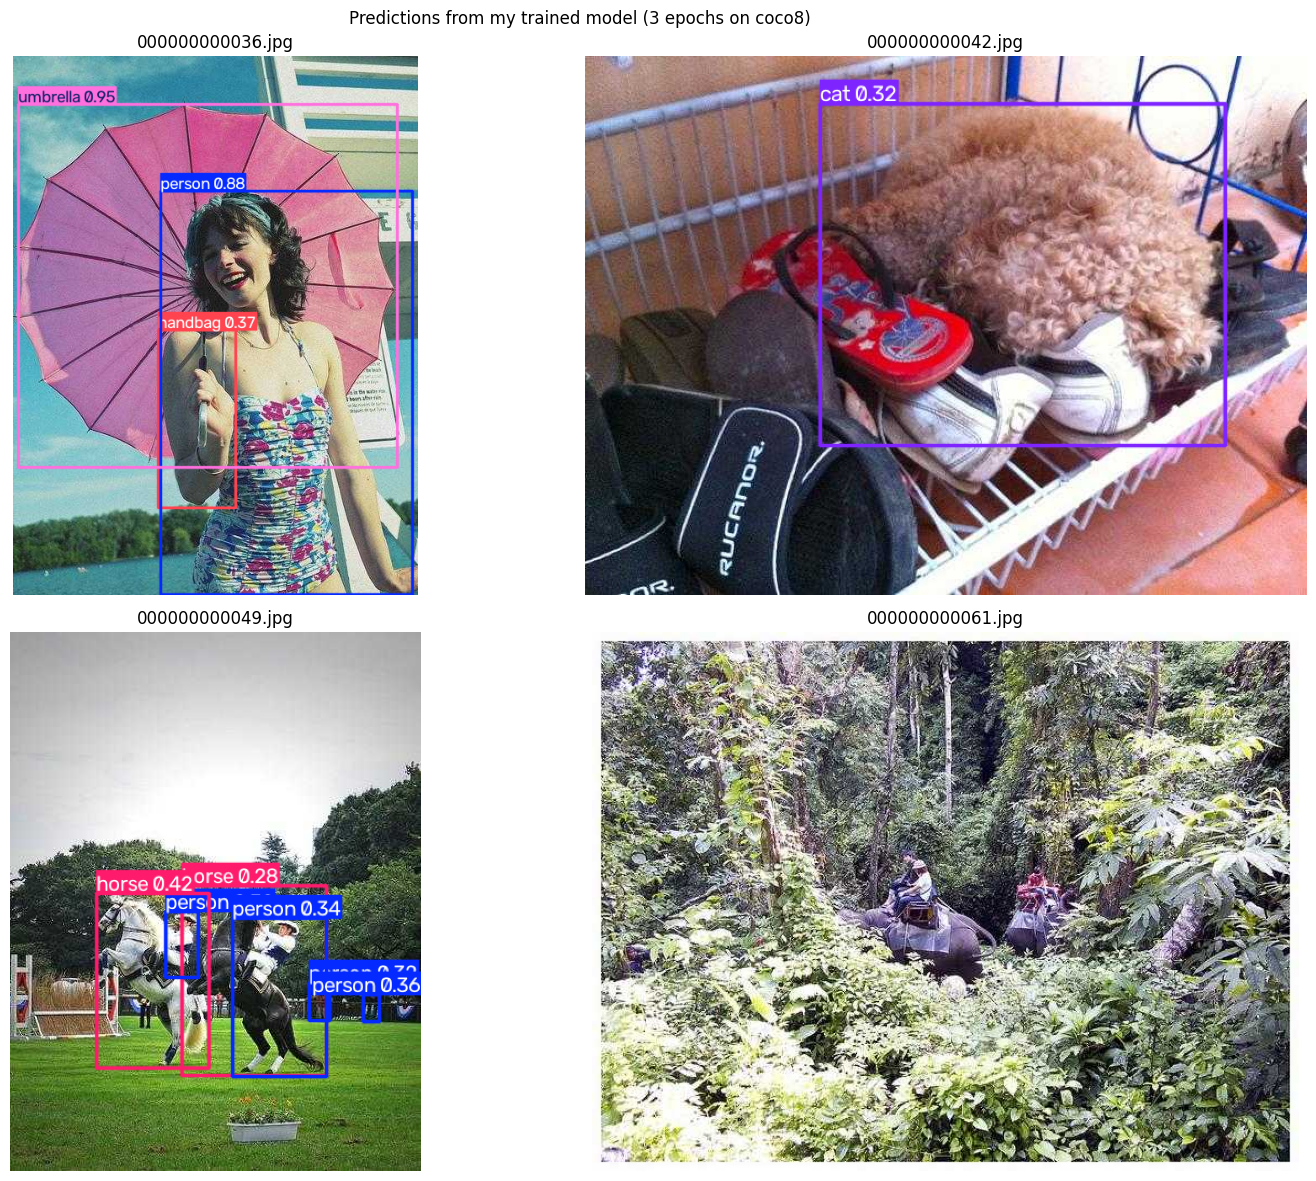

In [11]:
# TODO: Run predictions with the trained YOLO model and visualize
# - Pick one or more images and display bounding boxes/labels
trained_model = YOLO(str(best_weights))

# the 4 validation images of coco8 (not used for training)
val_dir = Path(data_config['path']) / data_config['val']
if not val_dir.is_absolute():
    val_dir = Path(DATASETS_DIR) / val_dir
val_images = sorted(val_dir.glob('*.jpg'))

predictions = trained_model.predict(source=[str(p) for p in val_images], imgsz=320, conf=0.25, verbose=False)

plt.figure(figsize=(16, 12))
for i, prediction in enumerate(predictions):
    found = [prediction.names[int(c)] for c in prediction.boxes.cls]
    print(f'{val_images[i].name}: {len(found)} detections -> {found}')

    plt.subplot(2, 2, i + 1)
    plt.imshow(cv2.cvtColor(prediction.plot(), cv2.COLOR_BGR2RGB))
    plt.title(val_images[i].name)
    plt.axis('off')
plt.suptitle('Predictions from my trained model (3 epochs on coco8)')
plt.tight_layout()
plt.show()

### Reflection
- Are the predictions what you expected?
- If performance is weak, why? (data size/quality, epochs, augmentations, etc.)
- What would you adjust for a more serious training run?
- What other arguments can you use for the training function.

**My answers:**

- **Are the predictions what you expected?** mostly yes. the trained model found the umbrella and the person, and the horses with their riders. but it called the dog a cat (confidence only 0.32), and it found nothing in the jungle picture with the elephants.
- **Why is performance weak?** coco8 has only 4 training images, and i trained for 3 epochs at 320 px on the CPU. the mAP50 stayed at about 0.62 in all 3 epochs, so the model didn't really learn anything new: what i see is basically the pretrained yolov8n. the misses also make sense at 320 px, because the elephants are small and dark in that picture, so most of their detail is gone.
- **What would i adjust for a serious run?** a real dataset with hundreds or thousands of labeled images, many more epochs (50 to 100+), a bigger image size like 640, and a GPU (Colab or Kaggle), with a separate validation set to watch for overfitting.
- **Other training arguments:** `lr0` (learning rate), `optimizer`, `patience` (early stopping), `freeze` (keep the first layers fixed), `device`, `cache`, `resume`, and the augmentation ones like `mosaic`, `fliplr` and `hsv_h`.